# Analisis Discord GitHub Ecosystem 2026
Notebook disusun mengikuti urutan latihan. **Target modelling: `archived`** (klasifikasi status arsip repository). Simpan CSV di folder yang sama dengan notebook.

## 1. Latihan: Data Loading

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from pathlib import Path

# Lokasi CSV relatif ke folder kerja VS Code
DATA_PATH = Path("discord_ecosystem_2026.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"File {DATA_PATH} tidak ditemukan. Letakkan CSV di folder kerja VS Code "
        "atau ganti DATA_PATH dengan lokasi lengkap file CSV."
    )
df = pd.read_csv(DATA_PATH)
print("Ukuran dataset:", df.shape)
display(df.head(10))
display(df.tail(5))
print("Kolom:", df.columns.tolist())
df.info()


Ukuran dataset: (1735, 26)


,id,name,full_name,owner,owner_type,is_official_discord,description,html_url,homepage,stars,...,topics,queried_topic,created_at,updated_at,pushed_at,repo_age_days,days_since_last_push,size_kb,is_fork,archived
0,1147094660,nanobot,HKUDS/nanobot,HKUDS,Organization,False,"Ultra-lightweight, open-source, self-hosted pe...",https://github.com/HKUDS/nanobot,https://nanobot.wiki,46967,...,agent-framework;ai-agent;ai-agents;chatbot;cha...,discord-bot,2026-02-01 07:16:15+00:00,2026-08-14 07:32:34+00:00,2026-08-14 03:22:22+00:00,194,0,57053,False,False
1,577603990,Open-Assistant,LAION-AI/Open-Assistant,LAION-AI,Organization,False,OpenAssistant is a chat-based assistant that u...,https://github.com/LAION-AI/Open-Assistant,https://open-assistant.io,37408,...,ai;assistant;chatgpt;discord-bot;language-mode...,discord-bot,2022-12-13 05:24:17+00:00,2026-08-14 01:26:24+00:00,2024-08-17 01:55:35+00:00,1340,727,35477,False,False
2,40484398,discord.js,discordjs/discord.js,discordjs,Organization,False,A powerful JavaScript library for interacting ...,https://github.com/discordjs/discord.js,https://discord.js.org,26783,...,bot;discord;discord-api;discord-bot;discord-se...,discord-bot,2015-08-10 13:36:26+00:00,2026-08-14 02:37:51+00:00,2026-08-13 19:10:25+00:00,4021,0,68288,False,False
3,575321313,LangBot,langbot-app/LangBot,langbot-app,Organization,False,Production-grade platform for building agentic...,https://github.com/langbot-app/LangBot,https://langbot.app,17404,...,agent;coze;deepseek;dify;dingtalk;discord;feis...,discord-bot-broad,2022-12-07 08:48:02+00:00,2026-08-14 07:05:13+00:00,2026-08-13 17:11:16+00:00,1345,0,55675,False,False
4,41179827,discord.py,Rapptz/discord.py,Rapptz,User,False,An API wrapper for Discord written in Python.,https://github.com/Rapptz/discord.py,http://discordpy.rtfd.org/en/latest,16139,...,bot;discord;discord-api;discord-bot;discord-py...,discord-bot,2015-08-21 22:19:08+00:00,2026-08-13 23:41:58+00:00,2026-07-27 18:33:15+00:00,4010,17,23106,False,False
5,54995014,discord-api-docs,discord/discord-api-docs,discord,Organization,True,Official Discord Developer Docs,https://github.com/discord/discord-api-docs,https://docs.discord.com/developers,6459,...,discord;discord-api;discordapp;memescale,official-discord-org,2016-03-29 17:11:53+00:00,2026-08-14 06:37:49+00:00,2026-08-14 00:25:10+00:00,3789,0,255598,False,False
6,1145582045,TitanBot,codebymitch/TitanBot,codebymitch,User,False,"A powerful, all-in-one Discord assistant built...",https://github.com/codebymitch/TitanBot,https://discord.gg/QnWNz2dKCE,6404,...,all-in-one;automation;community;discord-bot,discord-bot,2026-01-30 00:40:44+00:00,2026-08-14 07:21:09+00:00,2026-08-05 17:37:19+00:00,196,8,3138,False,False
7,45356931,discordgo,bwmarrin/discordgo,bwmarrin,User,False,(Golang) Go bindings for Discord,https://github.com/bwmarrin/discordgo,NaN,5971,...,discord;discord-api;discordgo;go;golang,discord-api,2015-11-01 20:51:01+00:00,2026-08-12 13:46:34+00:00,2026-02-14 12:39:28+00:00,3938,180,2675,False,False
8,65681319,MusicBot,jagrosh/MusicBot,jagrosh,User,False,🎶 A Discord music bot that's easy to set up an...,https://github.com/jagrosh/MusicBot,https://jmusicbot.com,5753,...,discord;discord-bot;java;jda;music;music-bot;m...,discord-bot,2016-08-14 18:46:29+00:00,2026-08-13 01:19:10+00:00,2024-11-16 15:22:38+00:00,3651,635,7798,False,False
9,386913925,discordo,ayn2op/discordo,ayn2op,User,False,"A lightweight, secure, and feature-rich Discor...",https://github.com/ayn2op/discordo,NaN,5730,...,client;cross-platform;discord;discord-bot;disc...,discord-bot,2021-07-17 11:00:48+00:00,2026-08-14 04:02:50+00:00,2026-08-13 05:27:33+00:00,1853,1,14666,False,False


,id,name,full_name,owner,owner_type,is_official_discord,description,html_url,homepage,stars,...,topics,queried_topic,created_at,updated_at,pushed_at,repo_age_days,days_since_last_push,size_kb,is_fork,archived
1730,1327717969,discord-server-booster-client,bodyforemanravine/discord-server-booster-client,bodyforemanravine,User,False,Discord Server Booster Client is an automated ...,https://github.com/bodyforemanravine/discord-s...,NaN,1,...,discord;discord-boost-bot;discord-boost-tool;d...,discord-server,2026-08-08 12:18:55+00:00,2026-08-08 12:25:05+00:00,2026-08-08 12:23:49+00:00,5,5,770,False,False
1731,457280566,Shorty,itsreyaansh/Shorty,itsreyaansh,User,False,A Link Shortener Bot That Lets You Shorten You...,https://github.com/itsreyaansh/Shorty,NaN,1,...,bot;discord;discord-bot;discord-py;discord-ser...,discord-server,2022-02-09 08:56:26+00:00,2025-07-23 13:18:13+00:00,2023-06-17 08:12:13+00:00,1646,1153,800,False,False
1732,259873933,pyke-bot,ZykingAut/pyke-bot,ZykingAut,User,False,NaN,https://github.com/ZykingAut/pyke-bot,NaN,1,...,bot;discord-bot;discord-server,discord-server,2020-04-29 08:53:06+00:00,2021-10-15 14:46:03+00:00,2022-12-13 05:15:09+00:00,2297,1340,912,False,False
1733,1040399166,pipewire-rs,discord/pipewire-rs,discord,Organization,True,NaN,https://github.com/discord/pipewire-rs,NaN,1,...,NaN,official-discord-org,2025-08-18 23:24:05+00:00,2025-08-20 21:05:14+00:00,2026-02-13 18:18:19+00:00,360,181,655,False,False
1734,1218343045,arborium-rt,discord/arborium-rt,discord,Organization,True,tree-sitter syntax highlighting for the browse...,https://github.com/discord/arborium-rt,NaN,0,...,NaN,official-discord-org,2026-04-22 19:27:08+00:00,2026-08-10 22:00:30+00:00,2026-08-10 22:00:00+00:00,113,3,608,False,False


Kolom: ['id', 'name', 'full_name', 'owner', 'owner_type', 'is_official_discord', 'description', 'html_url', 'homepage', 'stars', 'forks', 'watchers', 'open_issues', 'stars_per_day', 'language', 'license', 'topics', 'queried_topic', 'created_at', 'updated_at', 'pushed_at', 'repo_age_days', 'days_since_last_push', 'size_kb', 'is_fork', 'archived']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1735 entries, 0 to 1734
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    1735 non-null   int64  
 1   name                  1735 non-null   object 
 2   full_name             1735 non-null   object 
 3   owner                 1735 non-null   object 
 4   owner_type            1735 non-null   object 
 5   is_official_discord   1735 non-null   bool   
 6   description           1697 non-null   object 
 7   html_url              1735 non-null   object 
 8   homepage              624 non-

**Penjelasan baris kode:** `import` memuat pustaka; `DATA_PATH` menentukan nama CSV; `pd.read_csv` membaca CSV; `shape` menghitung baris/kolom; `head`/`tail` menampilkan sampel; `columns` menunjukkan nama fitur; `info` menunjukkan tipe data dan nilai non-null. Simpan CSV di folder kerja VS Code.

## 2. Data Cleaning
Periksa nilai kosong dan duplikat, lalu hilangkan duplikat. Nilai kosong akan ditangani melalui pipeline saat modelling agar tidak terjadi kebocoran data.

In [4]:
print("Missing values:\n", df.isna().sum().sort_values(ascending=False))
print("Duplikat:", df.duplicated().sum())
df = df.drop_duplicates().copy()
print("Ukuran setelah pembersihan:", df.shape)

Missing values:
 homepage                1111
license                  372
topics                    84
language                  59
description               38
name                       0
is_official_discord        0
id                         0
full_name                  0
owner                      0
stars                      0
html_url                   0
owner_type                 0
forks                      0
stars_per_day              0
open_issues                0
watchers                   0
queried_topic              0
created_at                 0
updated_at                 0
pushed_at                  0
repo_age_days              0
days_since_last_push       0
size_kb                    0
is_fork                    0
archived                   0
dtype: int64
Duplikat: 0
Ukuran setelah pembersihan: (1735, 26)


**Penjelasan:** `isna().sum()` menghitung nilai hilang per kolom; `duplicated().sum()` menghitung baris duplikat; `drop_duplicates().copy()` menghapus duplikat dan menyalin hasil; `shape` menunjukkan ukuran sesudah pembersihan. Nilai hilang pada fitur akan diisi dalam pipeline setelah splitting untuk menghindari kebocoran data.

## 3. Latihan: Data Cleaning dan Transformation
Konversi tanggal dan buat fitur numerik tambahan tanpa mengubah target.

In [5]:
for col in ["created_at", "updated_at", "pushed_at"]:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce", utc=True)
        df[col + "_year"] = df[col].dt.year

for col in ["stars", "forks", "watchers", "open_issues", "stars_per_day", "repo_age_days", "days_since_last_push", "size_kb"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

if "stars" in df.columns:
    df["log_stars"] = np.log1p(df["stars"].clip(lower=0))
print(df.dtypes.to_string())
display(df.head())

id                                    int64
name                                 object
full_name                            object
owner                                object
owner_type                           object
is_official_discord                    bool
description                          object
html_url                             object
homepage                             object
stars                                 int64
forks                                 int64
watchers                              int64
open_issues                           int64
stars_per_day                       float64
language                             object
license                              object
topics                               object
queried_topic                        object
created_at              datetime64[ns, UTC]
updated_at              datetime64[ns, UTC]
pushed_at               datetime64[ns, UTC]
repo_age_days                         int64
days_since_last_push            

,id,name,full_name,owner,owner_type,is_official_discord,description,html_url,homepage,stars,...,pushed_at,repo_age_days,days_since_last_push,size_kb,is_fork,archived,created_at_year,updated_at_year,pushed_at_year,log_stars
0,1147094660,nanobot,HKUDS/nanobot,HKUDS,Organization,False,"Ultra-lightweight, open-source, self-hosted pe...",https://github.com/HKUDS/nanobot,https://nanobot.wiki,46967,...,2026-08-14 03:22:22+00:00,194,0,57053,False,False,2026,2026,2026,10.757222
1,577603990,Open-Assistant,LAION-AI/Open-Assistant,LAION-AI,Organization,False,OpenAssistant is a chat-based assistant that u...,https://github.com/LAION-AI/Open-Assistant,https://open-assistant.io,37408,...,2024-08-17 01:55:35+00:00,1340,727,35477,False,False,2022,2026,2024,10.529667
2,40484398,discord.js,discordjs/discord.js,discordjs,Organization,False,A powerful JavaScript library for interacting ...,https://github.com/discordjs/discord.js,https://discord.js.org,26783,...,2026-08-13 19:10:25+00:00,4021,0,68288,False,False,2015,2026,2026,10.195560
3,575321313,LangBot,langbot-app/LangBot,langbot-app,Organization,False,Production-grade platform for building agentic...,https://github.com/langbot-app/LangBot,https://langbot.app,17404,...,2026-08-13 17:11:16+00:00,1345,0,55675,False,False,2022,2026,2026,9.764513
4,41179827,discord.py,Rapptz/discord.py,Rapptz,User,False,An API wrapper for Discord written in Python.,https://github.com/Rapptz/discord.py,http://discordpy.rtfd.org/en/latest,16139,...,2026-07-27 18:33:15+00:00,4010,17,23106,False,False,2015,2026,2026,9.689056


**Penjelasan:** perulangan `for` memproses kolom hanya jika ada; `to_datetime(..., errors="coerce", utc=True)` mengonversi tanggal dan memberi NaT pada nilai tidak valid; `.dt.year` membuat fitur tahun; `to_numeric` mengonversi angka; `np.log1p` mentransformasi jumlah stars dengan log(1+x) dan `clip` mencegah angka negatif.

## 4. Latihan EDA & ExDA
EDA: ringkasan statistik, distribusi status arsip, dan hubungan antarf fitur. ExDA: pemeriksaan outlier serta perbandingan antarkelompok.

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
id,1735.0,NaN,NaN,NaN,464744243.42536,2977472.0,237816681.0,378757338.0,632139111.5,1329647482.0,318229715.782248
name,1735,1651,discord-bot,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
full_name,1735,1735,HKUDS/nanobot,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
owner,1735,1469,discord,88,NaN,NaN,NaN,NaN,NaN,NaN,NaN
owner_type,1735,2,User,1337,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_official_discord,1735,2,False,1647,NaN,NaN,NaN,NaN,NaN,NaN,NaN
description,1697,1692,An API wrapper for Discord written in Python.,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
html_url,1735,1735,https://github.com/HKUDS/nanobot,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
homepage,624,616,https://discord.gg/codes,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
stars,1735.0,NaN,NaN,NaN,279.755043,0.0,8.0,43.0,163.0,46967.0,1751.503986


Distribusi archived:
 archived
False    1438
True      297
Name: count, dtype: int64


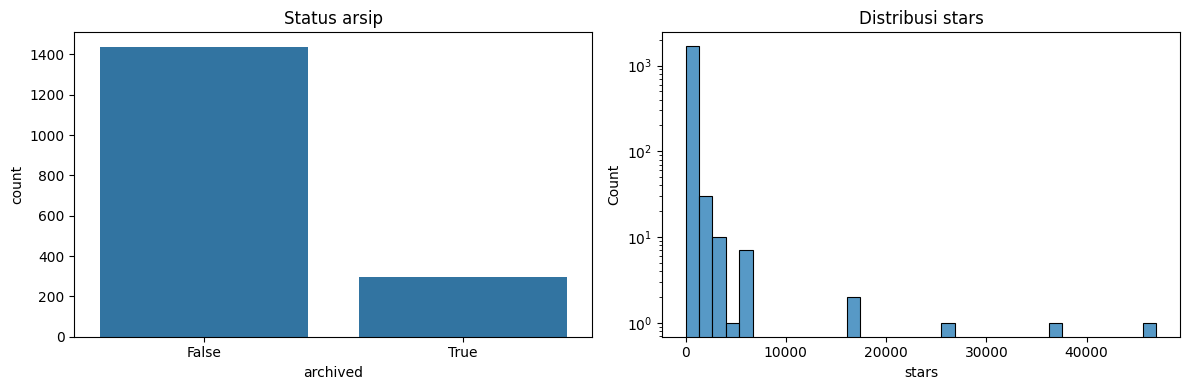

In [6]:
display(df.describe(include="all").T)
print("Distribusi archived:\n", df["archived"].value_counts(dropna=False))
fig, axes = plt.subplots(1, 2, figsize=(12,4))
sns.countplot(data=df, x="archived", ax=axes[0]); axes[0].set_title("Status arsip")
sns.histplot(data=df, x="stars", bins=35, ax=axes[1]); axes[1].set_title("Distribusi stars")
axes[1].set_yscale("log")
plt.tight_layout(); plt.show()

**Penjelasan:** `describe(include="all")` merangkum statistik; `value_counts` menghitung kelas target; `countplot` menggambar frekuensi status archived; `histplot` memperlihatkan distribusi stars; `set_yscale("log")` membantu membaca rentang frekuensi; `show` menampilkan grafik.

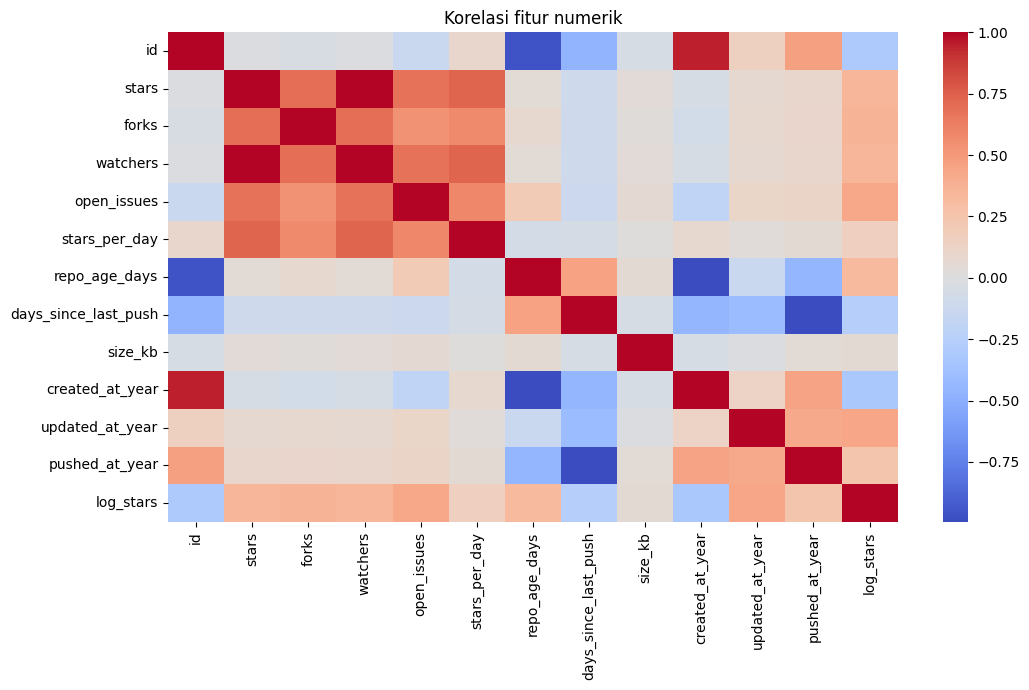

,jumlah
language,
Python,531
JavaScript,467
TypeScript,247
C#,70
Tidak diketahui,59
Go,52
Java,49
Rust,45
C++,39


Outlier stars (aturan IQR): 205


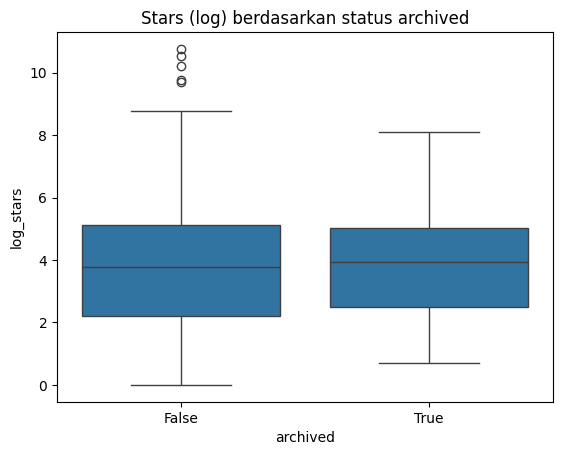

In [7]:
numeric = df.select_dtypes(include="number")
plt.figure(figsize=(11,7))
sns.heatmap(numeric.corr(), cmap="coolwarm", center=0)
plt.title("Korelasi fitur numerik"); plt.tight_layout(); plt.show()

if "language" in df.columns:
    display(df["language"].fillna("Tidak diketahui").value_counts().head(10).rename("jumlah").to_frame())
if "stars" in df.columns:
    q1, q3 = df["stars"].quantile([.25,.75]); iqr=q3-q1
    print("Outlier stars (aturan IQR):", ((df["stars"] < q1-1.5*iqr) | (df["stars"] > q3+1.5*iqr)).sum())
    sns.boxplot(data=df, x="archived", y="log_stars")
    plt.title("Stars (log) berdasarkan status archived"); plt.show()

**Penjelasan:** `select_dtypes` mengambil fitur numerik; `corr` menghitung korelasi; `heatmap` memvisualisasikannya; `value_counts().head(10)` melihat sepuluh bahasa paling umum; kuartil Q1/Q3 dan IQR digunakan menandai nilai ekstrem; `boxplot` membandingkan distribusi stars setelah transformasi log. Outlier tidak otomatis dihapus.

## 5. Data Processing
Pilih fitur relevan, lalu siapkan preprocessing: imputasi median untuk angka, imputasi modus dan one-hot encoding untuk kategori. Fitting dilakukan **hanya pada data training**.

In [16]:

# =====================================================
# 5. DATA PROCESSING - DISCORD ECOSYSTEM 2026
# =====================================================

import pandas as pd
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 1. Menentukan target prediksi
target = "archived"

# 2. Menentukan fitur yang digunakan
feature_cols = [
    "stars",
    "forks",
    "watchers",
    "open_issues",
    "stars_per_day",
    "repo_age_days",
    "days_since_last_push",
    "size_kb",
    "log_stars",
    "created_at_year",
    "language",
    "license",
    "owner_type",
    "is_fork",
    "is_official_discord"
]

# 3. Memilih fitur yang tersedia di dataset
feature_cols = [
    col for col in feature_cols
    if col in df.columns
]

# 4. Memastikan target tersedia
if target not in df.columns:
    raise ValueError("Kolom archived tidak ditemukan!")

# 5. Menghapus baris dengan target kosong
model_df = df.dropna(subset=[target]).copy()

# 6. Memisahkan fitur dan target
X = model_df[feature_cols].copy()

# 7. Normalisasi target tanpa FutureWarning
y_raw = (
    model_df[target]
    .astype("string")
    .str.strip()
    .str.lower()
)

# 8. Mengubah target menjadi angka 0 dan 1
y = y_raw.map({
    "true": 1,
    "false": 0,
    "1": 1,
    "0": 0
})

# 9. Memilih data dengan target valid
valid = y.isin([0, 1])

X = X.loc[valid].copy()
y = y.loc[valid].astype(int)

if X.empty:
    raise ValueError("Tidak ada label archived yang valid!")

# 10. Memisahkan fitur numerik dan kategori
num_cols = X.select_dtypes(
    include="number"
).columns.tolist()

cat_cols = [
    col for col in X.columns
    if col not in num_cols
]

# 11. Menangani nilai kategori yang kosong
if cat_cols:
    X[cat_cols] = (
        X[cat_cols]
        .astype("object")
        .where(X[cat_cols].notna(), np.nan)
    )

# 12. Pipeline preprocessing numerik
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# 13. Pipeline preprocessing kategori
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="most_frequent"
    )),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

# 14. Menggabungkan preprocessing
preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

# 15. Menampilkan hasil data processing
print("=== HASIL DATA PROCESSING ===")
print("Jumlah data:", len(X))
print("Jumlah fitur:", len(feature_cols))

print("\nFitur numerik:")
print(num_cols)

print("\nFitur kategori:")
print(cat_cols)

print("\nDistribusi target:")
print(y.value_counts())

print("\nData Processing berhasil!")


=== HASIL DATA PROCESSING ===
Jumlah data: 1735
Jumlah fitur: 15

Fitur numerik:
['stars', 'forks', 'watchers', 'open_issues', 'stars_per_day', 'repo_age_days', 'days_since_last_push', 'size_kb', 'log_stars', 'created_at_year']

Fitur kategori:
['language', 'license', 'owner_type', 'is_fork', 'is_official_discord']

Distribusi target:
archived
0    1438
1     297
Name: count, dtype: int64

Data Processing berhasil!


**Penjelasan:** `target` adalah label prediksi; `feature_cols` menentukan fitur yang tersedia; `X` adalah fitur dan `y` adalah label; `select_dtypes` memisahkan numerik dan kategorikal; `SimpleImputer` mengisi nilai hilang; `StandardScaler` menstandardisasi numerik; `OneHotEncoder` mengubah kategori menjadi indikator; `ColumnTransformer` menerapkan perlakuan sesuai tipe kolom. Pipeline di-fit pada data training saja.

## 6. Data Splitting
Gunakan 80% training dan 20% testing, dengan stratifikasi bila tiap kelas mempunyai cukup sampel.

In [9]:
from sklearn.model_selection import train_test_split
if y.nunique() < 2:
    raise ValueError("Target archived hanya memiliki satu kelas. Klasifikasi tidak bisa dilatih.")
stratify = y if y.value_counts().min() >= 2 else None
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=stratify)
print("Training:", X_train.shape, "Testing:", X_test.shape)

Training: (1388, 15) Testing: (347, 15)


**Penjelasan:** `train_test_split` membagi data 80% train dan 20% test; `random_state=42` membuat pembagian konsisten; `stratify=y` mempertahankan proporsi kelas jika memungkinkan; pemeriksaan `nunique` memastikan klasifikasi memiliki dua kelas.

## 7. Latihan: Data Splitting
Verifikasi tidak ada indeks yang tumpang tindih dan lihat proporsi label.

In [10]:
print("Indeks tumpang tindih:", len(set(X_train.index) & set(X_test.index)))
print("Persentase training:\n", y_train.value_counts(normalize=True).round(3))
print("Persentase testing:\n", y_test.value_counts(normalize=True).round(3))
assert len(X_train) + len(X_test) == len(X)

Indeks tumpang tindih: 0
Persentase training:
 archived
0    0.829
1    0.171
Name: proportion, dtype: float64
Persentase testing:
 archived
0    0.83
1    0.17
Name: proportion, dtype: float64


**Penjelasan:** irisan indeks train/test harus kosong agar tidak ada sampel yang muncul di kedua bagian; `value_counts(normalize=True)` menghitung proporsi label; `assert` memeriksa total sampel tetap sama.

## 8. Pembangunan Model (Modelling)
Random Forest, metrik klasifikasi, confusion matrix, dan perbandingan dengan baseline kelas mayoritas.

Akurasi: 0.7983
Balanced accuracy: 0.6359
              precision    recall  f1-score   support

           0       0.88      0.88      0.88       288
           1       0.40      0.39      0.40        59

    accuracy                           0.80       347
   macro avg       0.64      0.64      0.64       347
weighted avg       0.80      0.80      0.80       347



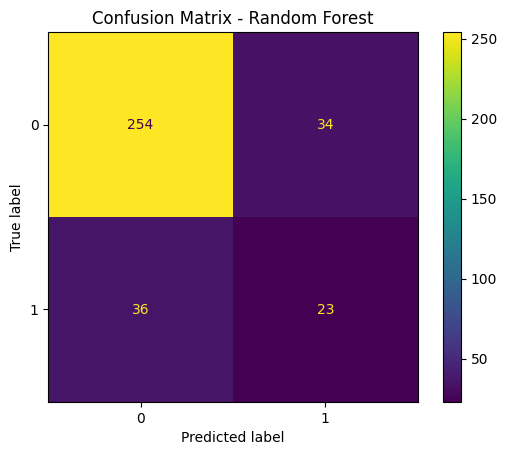

Baseline akurasi: 0.83


In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, balanced_accuracy_score

model = Pipeline([("preprocess", preprocessor), ("classifier", RandomForestClassifier(n_estimators=200, random_state=42, class_weight="balanced"))])
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Akurasi:", round(accuracy_score(y_test, y_pred), 4))
print("Balanced accuracy:", round(balanced_accuracy_score(y_test, y_pred), 4))
print(classification_report(y_test, y_pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Confusion Matrix - Random Forest"); plt.show()

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print("Baseline akurasi:", round(accuracy_score(y_test, baseline.predict(X_test)), 4))

**Penjelasan:** `RandomForestClassifier` melatih banyak pohon keputusan; `Pipeline` menyatukan preprocessing dan model; `fit` melatih pada train; `predict` memprediksi test; `accuracy_score` menghitung proporsi prediksi benar; `balanced_accuracy_score` merata-ratakan recall tiap kelas; `classification_report` memberi precision, recall, F1; `ConfusionMatrixDisplay` memvisualisasikan kesalahan; `DummyClassifier` menjadi pembanding kelas mayoritas.

### Kesimpulan
Bandingkan akurasi dan balanced accuracy model dengan baseline. Perhatikan recall dan precision masing-masing kelas, terutama jika data tidak seimbang. Hasil akhir muncul setelah seluruh cell dijalankan.